In [ ]:
import os
os.environ['keras_backend'] = 'torch'

In [ ]:
import keras
import gdown
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [ ]:
file_id = "1XssmeqfQ_KXCLJ-nKY5yLpJHsSwojDMx"
url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, "dataset.zip", quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1XssmeqfQ_KXCLJ-nKY5yLpJHsSwojDMx
To: /content/dataset.zip
100%|██████████| 17.3M/17.3M [00:00<00:00, 19.4MB/s]


'dataset.zip'

In [ ]:
with zipfile.ZipFile("dataset.zip", "r") as f:
  f.extractall("dataset")

In [ ]:
train_dir = "./dataset/train"
val_dir = "./dataset/val"


images = []
masks = []

val_images = []
val_masks = []

for f in os.listdir(train_dir):
  if f.endswith(".png"):
    if "_outline" in f:
      masks.append(f)
    else:
      images.append(f)

for f in os.listdir(val_dir):
  if f.endswith(".png"):
    if "_outline" in f:
      val_masks.append(f)
    else:
      val_images.append(f)

print("Размер images:", len(images))
print("Размер masks:", len(masks))
print("Размер val_images:", len(val_images))
print("Размер val_masks:", len(val_masks))

Размер images: 36
Размер masks: 36
Размер val_images: 10
Размер val_masks: 10


(512, 512, 3)
(512, 512)
[  0.   8.  16.  30.  32.  43.  62. 113. 128. 189. 232. 245. 252. 253.
 255.]


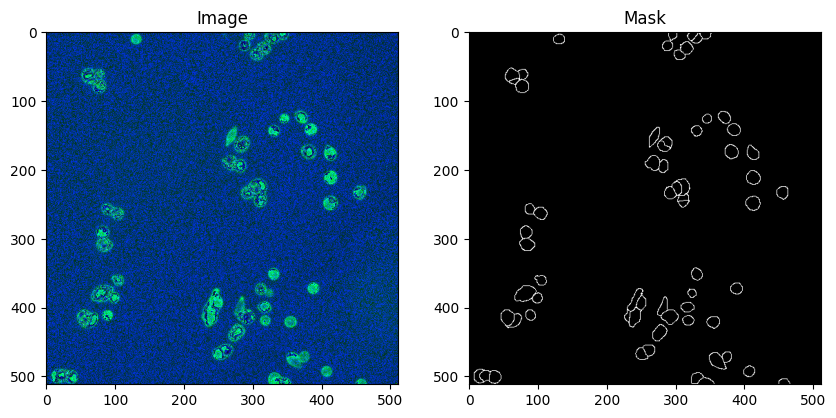

In [ ]:
img = np.array(Image.open(os.path.join(train_dir, images[0])))
mask = np.array(Image.open(os.path.join(train_dir, images[0].replace(".png", "_outline.png"))), dtype=np.float32)

print(img.shape)
print(mask.shape)
print(np.unique(mask))

plt.figure(figsize=(10,5))

plt.subplot(121)
plt.imshow(img)
plt.title("Image")

plt.subplot(122)
plt.imshow(mask, cmap="gray")
plt.title("Mask")

plt.show()

In [ ]:
def random_crop(image, mask, min_pixel=50, crop_size=128):
  h, w = image.shape[:2]

  for _ in range(50):
    x = np.random.randint(0, w - crop_size + 1)
    y = np.random.randint(0, h - crop_size + 1)

    image_crop = image[
        y:y+crop_size,
        x:x+crop_size
    ]

    mask_crop = mask[
        y:y+crop_size,
        x:x+crop_size
    ]

    if mask_crop.sum() > min_pixel:
      return image_crop, mask_crop

  return image_crop, mask_crop

In [ ]:
X_train = []
Y_train = []

for name in images:
  img = np.array(Image.open(os.path.join(train_dir, name)))
  mask = np.array(
      Image.open(
          os.path.join(
              train_dir,
              name.replace(".png", "_outline.png")
          )
      ),
      dtype=np.float32
  )
  mask = np.where(mask > 0, 1.0, 0.0)

  for _ in range(20):
    img_crop, mask_crop = random_crop(img, mask, crop_size=128)
    mask_crop = np.reshape(mask_crop, (128, 128, 1))

    X_train.append(img_crop.astype(np.float32) / 255)
    Y_train.append(mask_crop)

X_train = np.array(X_train)
Y_train = np.array(Y_train)

In [ ]:
print(X_train.shape)
print(Y_train.shape)

(720, 128, 128, 3)
(720, 128, 128, 1)


In [ ]:
X_val = []
Y_val = []

for img_name in val_images:
  image = np.array(
      Image.open(
          os.path.join(val_dir, img_name)
      )
  )

  mask = np.array(
      Image.open(
          os.path.join(
              val_dir,
              img_name.replace(".png", "_outline.png")
          )
      ),
      dtype=np.float32
  )

  mask = np.where(mask > 0, 1.0, 0.0)
  mask= np.reshape(mask, (512, 512, 1))

  X_val.append(image.astype(np.float32) / 255)
  Y_val.append(mask)

X_val = np.array(X_val)
Y_val = np.array(Y_val)

In [ ]:
print(X_val.shape)
print(Y_val.shape)

(10, 512, 512, 3)
(10, 512, 512, 1)


In [ ]:
class DiceLoss(keras.losses.Loss):

    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def call(self, y_true, y_pred):

        y_true = keras.ops.cast(y_true, "float32")
        y_pred = keras.ops.cast(y_pred, "float32")

        y_true = keras.ops.reshape(y_true, (-1,))
        y_pred = keras.ops.reshape(y_pred, (-1,))

        intersection = keras.ops.sum(y_true * y_pred)

        dice = (2.0 * intersection + self.smooth) / (keras.ops.sum(y_true) + keras.ops.sum(y_pred) + self.smooth)

        return 1.0 - dice


In [ ]:
class JaccardLoss(keras.losses.Loss):

    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def call(self, y_true, y_pred):

        y_true = keras.ops.cast(y_true, "float32")
        y_pred = keras.ops.cast(y_pred, "float32")

        y_true = keras.ops.reshape(y_true, (-1,))
        y_pred = keras.ops.reshape(y_pred, (-1,))

        intersection = keras.ops.sum(y_true * y_pred)

        union = keras.ops.sum(y_true) + keras.ops.sum(y_pred) - intersection

        iou = (intersection + self.smooth) / (union + self.smooth)

        return 1.0 - iou


In [ ]:
from keras import layers


def conv_block(x, filters):


    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    return x

In [ ]:
from keras import layers


def build_unet():

    inputs = keras.Input(
        shape=(None, None, 3)
    )

    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    bn = conv_block(p3, 256)

    u1 = layers.UpSampling2D((2, 2))(bn)
    u1 = layers.Concatenate()([u1, c3])

    c4 = conv_block(u1, 128)

    u2 = layers.UpSampling2D((2, 2))(c4)
    u2 = layers.Concatenate()([u2, c2])

    c5 = conv_block(u2, 64)

    u3 = layers.UpSampling2D((2, 2))(c5)
    u3 = layers.Concatenate()([u3, c1])

    c6 = conv_block(u3, 32)

    outputs = layers.Conv2D(
        filters=1,
        kernel_size=1,
        activation="sigmoid"
    )(c6)

    model = keras.Model(
        inputs,
        outputs,
        name="UNet"
    )

    return model

In [ ]:
model = build_unet()
model2 = build_unet()

model.summary()

Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, None,      │        896 │ input_layer_1[0]… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        128 │ conv2d_15[0][0]   │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_14 (ReLU)     │ (None, None,      │          0 │ batch_normalizat… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, None,      │      9,248 │ re_lu_14[0][0]    │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        128 │ conv2d_16[0][0]   │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_15 (ReLU)     │ (None, None,      │          0 │ batch_normalizat… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, None,      │          0 │ re_lu_15[0][0]    │
│ (MaxPooling2D)      │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, None,      │     18,496 │ max_pooling2d_3[… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        256 │ conv2d_17[0][0]   │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_16 (ReLU)     │ (None, None,      │          0 │ batch_normalizat… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, None,      │     36,928 │ re_lu_16[0][0]    │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        256 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_17 (ReLU)     │ (None, None,      │          0 │ batch_normalizat… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, None,      │          0 │ re_lu_17[0][0]    │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, None,      │     73,856 │ max_pooling2d_4[… │
│                     │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        512 │ conv2d_19[0][0] 

 Total params: 1,952,513 (7.45 MB)

 Trainable params: 1,949,697 (7.44 MB)

 Non-trainable params: 2,816 (11.00 KB)

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=DiceLoss(),
    metrics=['BinaryIoU']
)

In [ ]:
model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=JaccardLoss(),
    metrics=['BinaryIoU']
)

In [ ]:
history = model.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=35,
    batch_size=8
)

Epoch 1/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 24s 71ms/step - BinaryIoU: 0.3897 - loss: 0.8277 - val_BinaryIoU: 0.0279 - val_loss: 0.8841
Epoch 2/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - BinaryIoU: 0.4497 - loss: 0.7862 - val_BinaryIoU: 0.4875 - val_loss: 0.8671
Epoch 3/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - BinaryIoU: 0.4994 - loss: 0.7572 - val_BinaryIoU: 0.5054 - val_loss: 0.8527
Epoch 4/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - BinaryIoU: 0.5327 - loss: 0.7287 - val_BinaryIoU: 0.5518 - val_loss: 0.7780
Epoch 5/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - BinaryIoU: 0.5526 - loss: 0.7068 - val_BinaryIoU: 0.5615 - val_loss: 0.7022
Epoch 6/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - BinaryIoU: 0.5699 - loss: 0.6846 - val_BinaryIoU: 0.5554 - val_loss: 0.6813
Epoch 7/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - BinaryIoU: 0.5822 - loss: 0.6660 - val_BinaryIoU: 0.6037 - val_loss: 0.6470
Epoch 8/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - BinaryIoU: 0.5945 - loss: 0.6453 - val_Bina

In [ ]:
history2 = model2.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=35,
    batch_size=8
)

Epoch 1/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 24s 74ms/step - BinaryIoU: 0.3615 - loss: 0.9130 - val_BinaryIoU: 0.0300 - val_loss: 0.9413
Epoch 2/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - BinaryIoU: 0.4300 - loss: 0.8892 - val_BinaryIoU: 0.4855 - val_loss: 0.9299
Epoch 3/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - BinaryIoU: 0.4746 - loss: 0.8751 - val_BinaryIoU: 0.4629 - val_loss: 0.9098
Epoch 4/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - BinaryIoU: 0.5081 - loss: 0.8634 - val_BinaryIoU: 0.5437 - val_loss: 0.8858
Epoch 5/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - BinaryIoU: 0.5379 - loss: 0.8485 - val_BinaryIoU: 0.5400 - val_loss: 0.8380
Epoch 6/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - BinaryIoU: 0.5546 - loss: 0.8367 - val_BinaryIoU: 0.5691 - val_loss: 0.8194
Epoch 7/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - BinaryIoU: 0.5707 - loss: 0.8212 - val_BinaryIoU: 0.5611 - val_loss: 0.8099
Epoch 8/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - BinaryIoU: 0.5847 - loss: 0.8053 - val_Bina

In [ ]:
image = X_val[1]
true_mask = Y_val[1]

input_img = np.reshape(image, (1, 512, 512, 3))

pred_mask = model.predict(input_img)[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


In [ ]:
pred_mask2 = model2.predict(input_img)[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


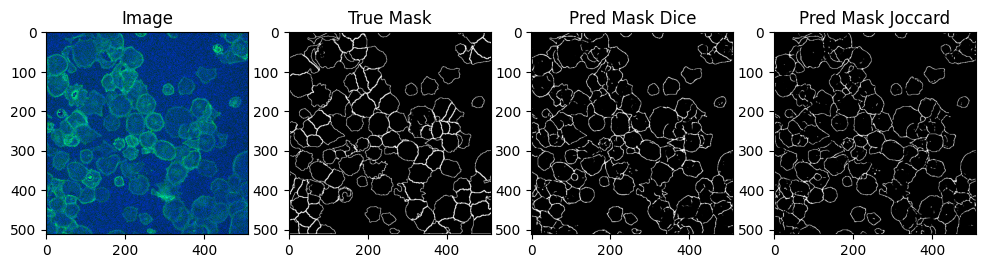

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

# оригинал
plt.subplot(1,4,1)
plt.imshow(image)
plt.title("Image")

# true mask
plt.subplot(1,4,2)
plt.imshow(true_mask, cmap="gray")
plt.title("True Mask")

# prediction dice
plt.subplot(1,4,3)
plt.imshow(pred_mask, cmap="gray")
plt.title("Pred Mask Dice")

# prediction Joccard
plt.subplot(1,4,4)
plt.imshow(pred_mask2, cmap="gray")
plt.title("Pred Mask Joccard")

plt.show()

In [ ]:
X_train_exp = []
Y_train_exp = []

for name in images:
  img = np.array(Image.open(os.path.join(train_dir, name)))
  mask = np.array(
      Image.open(
          os.path.join(
              train_dir,
              name.replace(".png", "_outline.png")
          )
      ),
      dtype=np.float32
  )
  mask = np.where(mask > 0, 1.0, 0.0)

  for _ in range(100):
    img_crop, mask_crop = random_crop(img, mask, min_pixel=20, crop_size=32)
    mask_crop = np.reshape(mask_crop, (32, 32, 1))

    X_train_exp.append(img_crop.astype(np.float32) / 255)
    Y_train_exp.append(mask_crop)

X_train_exp = np.array(X_train_exp)
Y_train_exp = np.array(Y_train_exp)

In [ ]:
model3 = build_unet()

model3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=DiceLoss(),
    metrics=['BinaryIoU']
)

In [ ]:
history = model3.fit(
    X_train_exp,
    Y_train_exp,
    validation_data=(X_val, Y_val),
    epochs=35,
    batch_size=36
)

Epoch 1/35
100/100 ━━━━━━━━━━━━━━━━━━━━ 36s 191ms/step - BinaryIoU: 0.3810 - loss: 0.7937 - val_BinaryIoU: 0.4763 - val_loss: 0.8767
Epoch 2/35
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - BinaryIoU: 0.4312 - loss: 0.7373 - val_BinaryIoU: 0.4725 - val_loss: 0.9008
Epoch 3/35
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - BinaryIoU: 0.4867 - loss: 0.6973 - val_BinaryIoU: 0.5007 - val_loss: 0.8789
Epoch 4/35
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - BinaryIoU: 0.5211 - loss: 0.6631 - val_BinaryIoU: 0.5020 - val_loss: 0.8052
Epoch 5/35
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - BinaryIoU: 0.5449 - loss: 0.6347 - val_BinaryIoU: 0.4486 - val_loss: 0.8002
Epoch 6/35
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - BinaryIoU: 0.5663 - loss: 0.6052 - val_BinaryIoU: 0.4351 - val_loss: 0.7777
Epoch 7/35
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - BinaryIoU: 0.5827 - loss: 0.5801 - val_BinaryIoU: 0.5648 - val_loss: 0.6468
Epoch 8/35
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - BinaryIoU: 0.5999 - loss: 

In [ ]:
pred_mask3 = model3.predict(input_img)[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


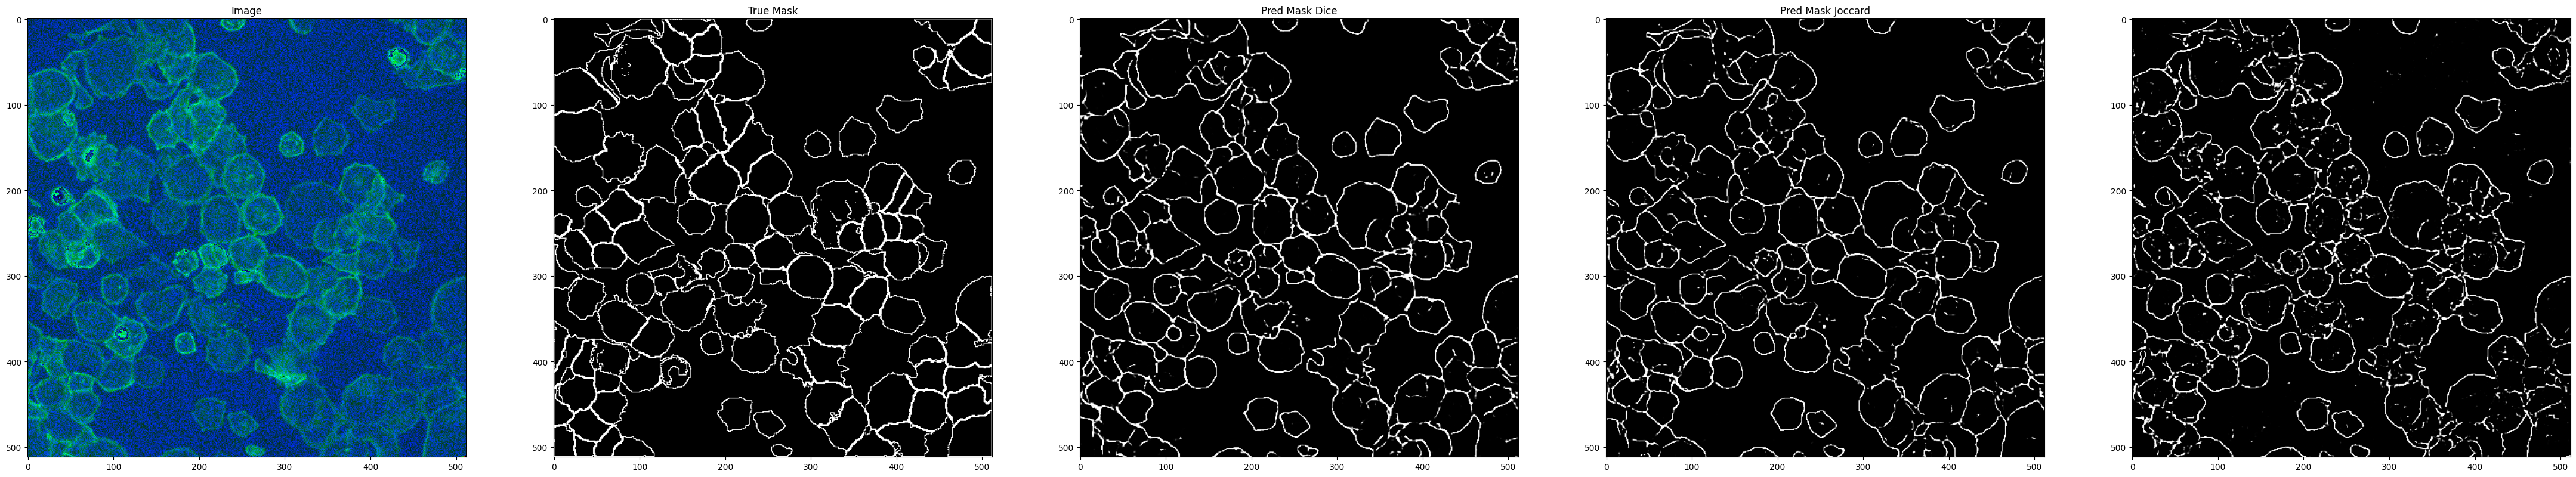

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(55,40))

# оригинал
plt.subplot(1,5,1)
plt.imshow(image)
plt.title("Image")

# true mask
plt.subplot(1,5,2)
plt.imshow(true_mask, cmap="gray")
plt.title("True Mask")

# prediction
plt.subplot(1,5,3)
plt.imshow(pred_mask, cmap="gray")
plt.title("Pred Mask Dice")

plt.subplot(1,5,4)
plt.imshow(pred_mask2, cmap="gray")
plt.title("Pred Mask Joccard")

plt.subplot(1,5,5)
plt.imshow(pred_mask3, cmap="grey")

plt.show()